# Tomato error analysis (Run 05)
Confusion matrix summed over six CNNs, images misclassified by most models, and picture grids of the hardest cases.

## 1. Settings, Drive, images

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix

PROJECT  = Path('/content/drive/MyDrive/thesis')
RUN_NAME = 'run05_balanced300_moderateaug'          # the run to analyse
HARD_MIN = 5                                        # a photo is 'hard' if at least this many of the models get it wrong
RUN_DIR  = PROJECT / 'experiments' / 'tomato' / RUN_NAME
FIG_DIR  = PROJECT / 'figures'; FIG_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = PROJECT / 'data/raw/agri_vision.zip'

UNZIP_DIR = Path('/content/data/agri_vision')
if not UNZIP_DIR.exists():
    UNZIP_DIR.mkdir(parents=True)
    !unzip -q "{ZIP_PATH}" -d "{UNZIP_DIR}"
    for inner in list(UNZIP_DIR.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"
ORIG_DIR = [p for p in UNZIP_DIR.rglob('*') if p.is_dir() and 'original' in p.name.lower()][0]
print('Run folder:', RUN_DIR, '| prediction files:', sorted(p.stem for p in (RUN_DIR / 'preds').glob('*.csv')))

Mounted at /content/drive
Run folder: /content/drive/MyDrive/thesis/experiments/tomato/run05_balanced300_moderateaug | prediction files: ['ConvNeXtTiny', 'DenseNet121', 'EfficientNetV2B0', 'InceptionV3', 'ResNet50', 'VGG16']


## 2. Load the predictions of every model

In [2]:
split = pd.read_csv(RUN_DIR / 'tomato_split.csv')
CLASSES = sorted(split.label.unique())
SHORT = [c.replace('Tomato_', '').replace('_', ' ') for c in CLASSES]

P = None
for f in sorted((RUN_DIR / 'preds').glob('*.csv')):
    p = pd.read_csv(f).rename(columns={'y_pred': f.stem})
    P = p if P is None else P.merge(p.drop(columns='y_true'), on='rel_path')
MODELS = [c for c in P.columns if c not in ('rel_path', 'y_true')]
P['n_wrong'] = (P[MODELS].values != P.y_true.values[:, None]).sum(1)
P['majority_pred'] = P[MODELS].mode(axis=1)[0].astype(int)
P['true_name'] = [SHORT[i] for i in P.y_true]
P['majority_name'] = [SHORT[i] for i in P.majority_pred]
print(len(P), 'test photos x', len(MODELS), 'models:', MODELS)
print('\nHow many models get each photo wrong:')
print(P.n_wrong.value_counts().sort_index().rename('photos').to_string())

148 test photos x 6 models: ['ConvNeXtTiny', 'DenseNet121', 'EfficientNetV2B0', 'InceptionV3', 'ResNet50', 'VGG16']

How many models get each photo wrong:
n_wrong
0    71
1    24
2     9
3    15
4    10
5    10
6     9


## 3. Confusion matrix summed over all models

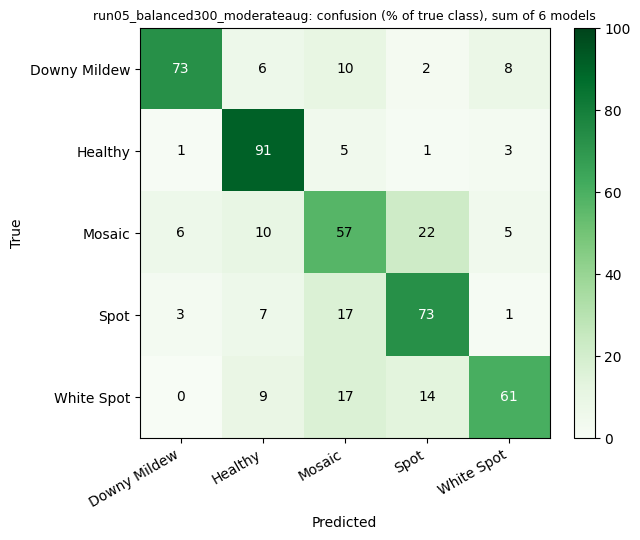

,pred Downy Mildew,pred Healthy,pred Mosaic,pred Spot,pred White Spot
true Downy Mildew,72.9,6.2,10.4,2.1,8.3
true Healthy,0.7,90.8,4.8,1.0,2.7
true Mosaic,6.3,9.9,57.2,22.1,4.5
true Spot,2.7,6.6,16.7,72.9,1.2
true White Spot,0.0,9.1,16.7,13.6,60.6


In [3]:
cm = sum(confusion_matrix(P.y_true, P[m], labels=range(len(CLASSES))) for m in MODELS)
cm_pct = 100 * cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm_pct, cmap='Greens', vmin=0, vmax=100)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f'{cm_pct[i, j]:.0f}', ha='center', va='center', color='white' if cm_pct[i, j] > 60 else 'black')
ax.set_xticks(range(len(CLASSES)), SHORT, rotation=30, ha='right'); ax.set_yticks(range(len(CLASSES)), SHORT)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'{RUN_NAME}: confusion (% of true class), sum of {len(MODELS)} models', fontsize=9)
plt.colorbar(im, fraction=0.046); plt.tight_layout()
fig.savefig(FIG_DIR / f'{RUN_NAME}_confusion_all_models.png', dpi=200); plt.show()
display(pd.DataFrame(cm_pct.round(1), index=['true ' + s for s in SHORT], columns=['pred ' + s for s in SHORT]))

## 4. Hard photos: wrong for at least `HARD_MIN` models

In [4]:
hard = P[P.n_wrong >= HARD_MIN].sort_values(['true_name', 'n_wrong'], ascending=[True, False])
agree = (hard[MODELS].values == hard.majority_pred.values[:, None]).sum(1)
hard = hard.assign(models_agreeing_on_wrong_label=agree)
cols = ['rel_path', 'true_name', 'majority_name', 'n_wrong', 'models_agreeing_on_wrong_label']
hard[cols].to_csv(RUN_DIR / 'hard_photos.csv', index=False)
print(f'{len(hard)} hard photos out of {len(P)} ({100*len(hard)/len(P):.0f}%). Saved to', RUN_DIR / 'hard_photos.csv')
print('\nHard photos per true disease -> what most models said instead:')
display(pd.crosstab(hard.true_name, hard.majority_name, margins=True, margins_name='Total'))
print('\nShare of each disease that is hard (%):')
display((100 * hard.true_name.value_counts() / P.true_name.value_counts()).round(1).fillna(0).rename('% hard').to_frame())

19 hard photos out of 148 (13%). Saved to /content/drive/MyDrive/thesis/experiments/tomato/run05_balanced300_moderateaug/hard_photos.csv

Hard photos per true disease -> what most models said instead:


majority_name,Downy Mildew,Healthy,Mosaic,Spot,White Spot,Total
true_name,,,,,,
Mosaic,1,3,0,7,1,12
Spot,1,2,1,0,0,4
White Spot,0,0,2,1,0,3
Total,2,5,3,8,1,19



Share of each disease that is hard (%):


,% hard
true_name,
Downy Mildew,0.0
Healthy,0.0
Mosaic,32.4
Spot,9.3
White Spot,27.3


## 5. Look at the hard photos

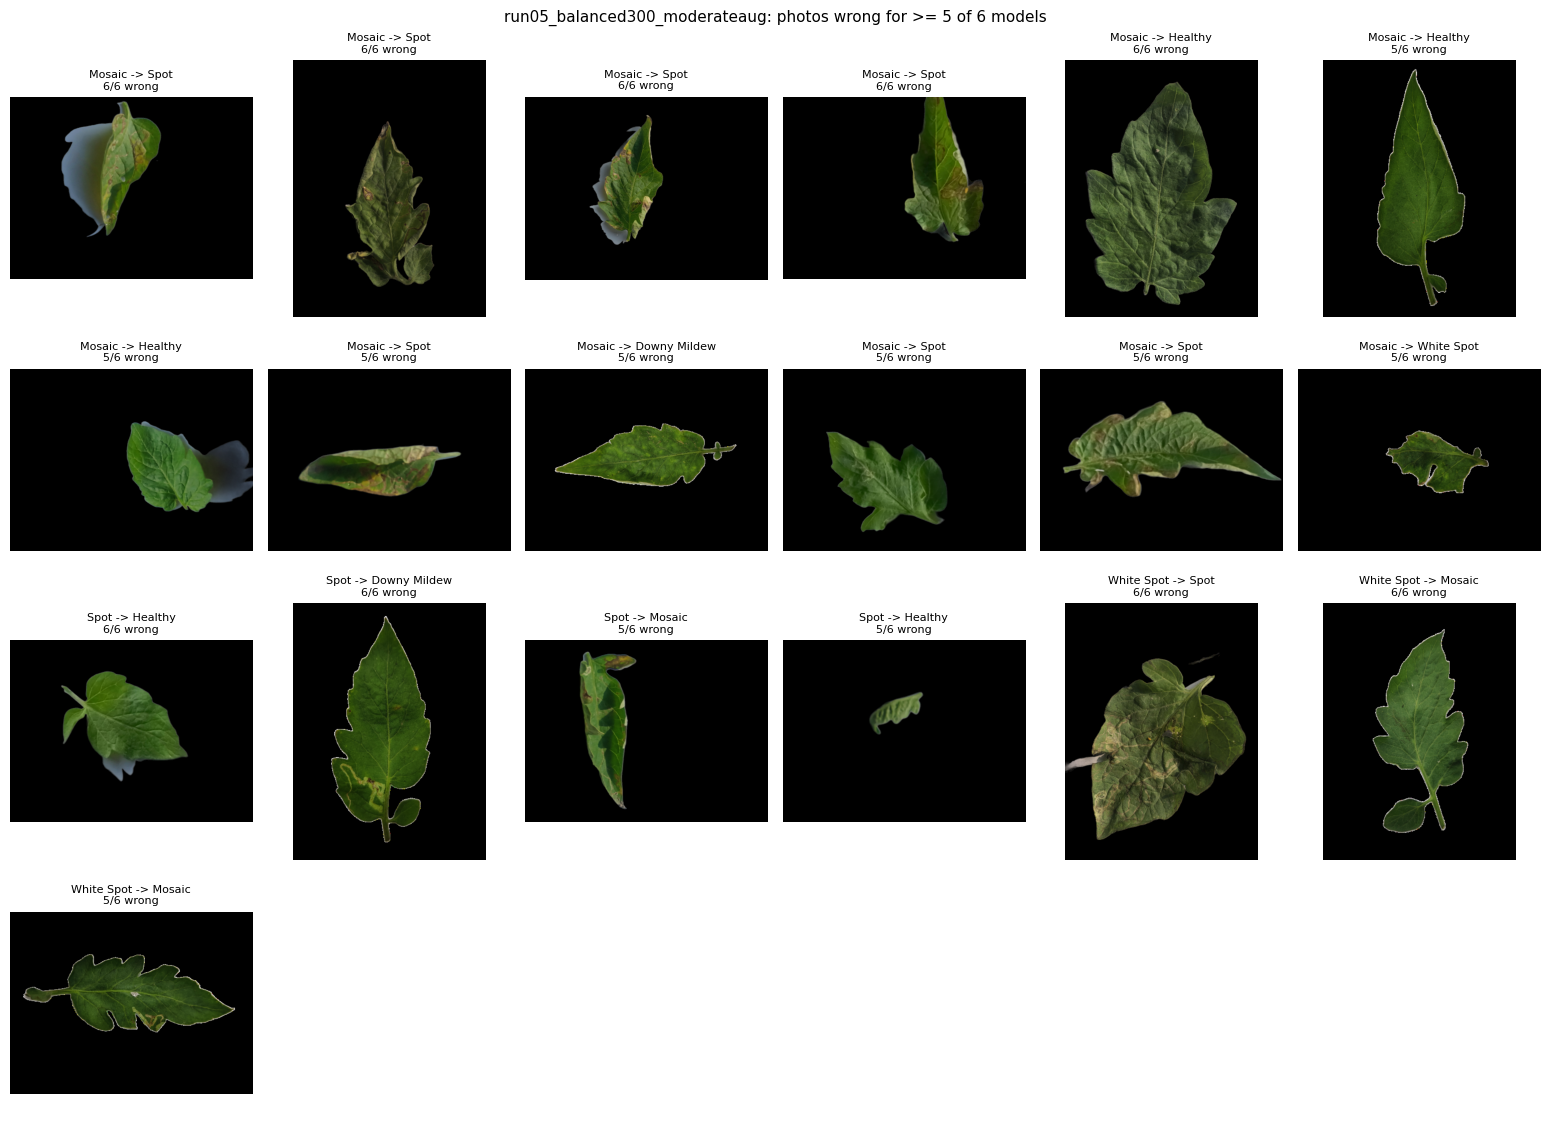

In [5]:
def grid(rows, title, fname, ncol=6):
    if len(rows) == 0:
        print('No photos for', title); return
    nrow = int(np.ceil(len(rows) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.9 * nrow), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        ax.imshow(Image.open(ORIG_DIR / r.rel_path).convert('RGB'))
        ax.set_title(f'{r.true_name} -> {r.majority_name}\n{r.n_wrong}/{len(MODELS)} wrong', fontsize=8)
    fig.suptitle(title, fontsize=11); plt.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150); plt.show()

grid(hard, f'{RUN_NAME}: photos wrong for >= {HARD_MIN} of {len(MODELS)} models', f'{RUN_NAME}_hard_photos.png')

## 6. Focus: Mosaic photos predicted as Spot

8 of 37 Mosaic test photos are called Spot by most models


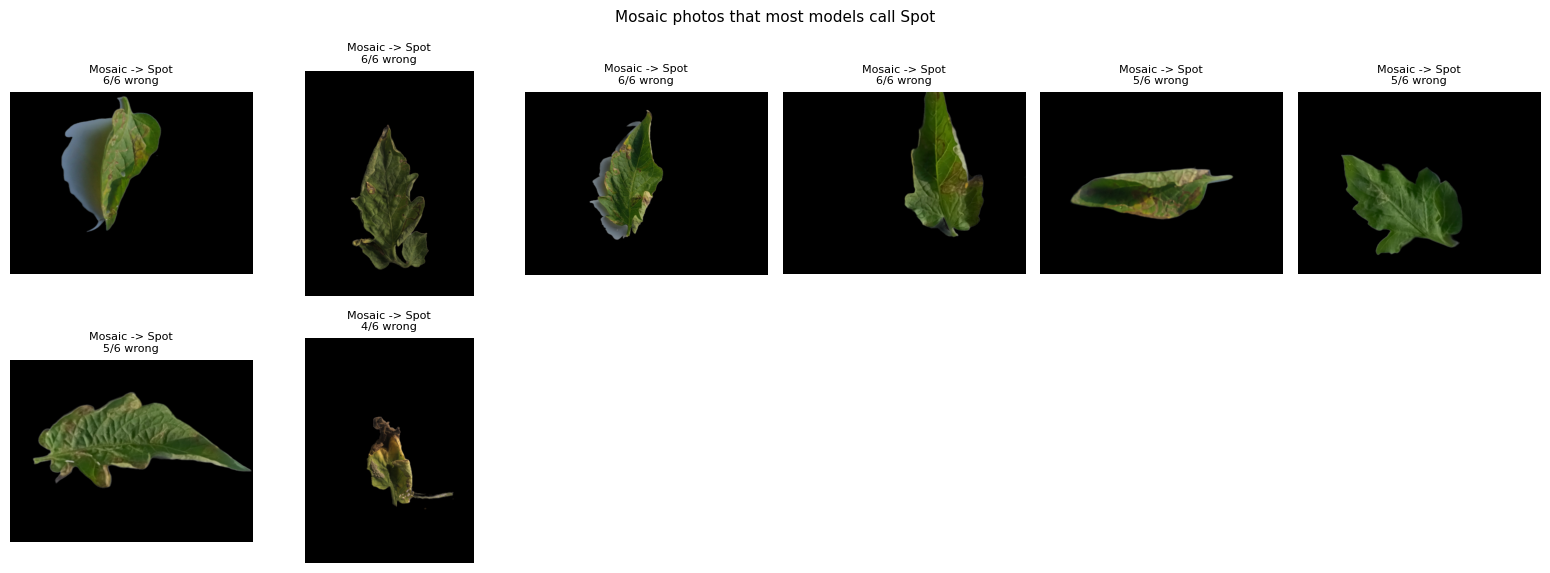

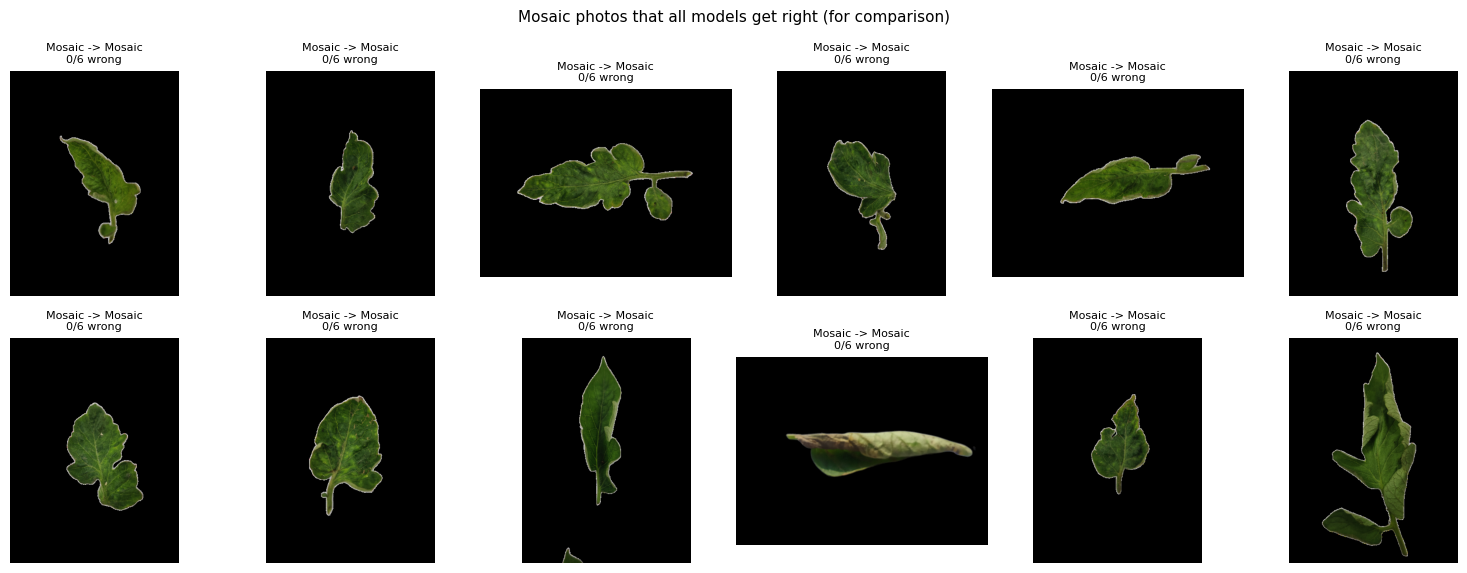

In [6]:
mos = P[(P.true_name == 'Mosaic') & (P.majority_name == 'Spot')].sort_values('n_wrong', ascending=False)
print(len(mos), 'of', (P.true_name == 'Mosaic').sum(), 'Mosaic test photos are called Spot by most models')
grid(mos, 'Mosaic photos that most models call Spot', f'{RUN_NAME}_mosaic_as_spot.png')

# For comparison: Mosaic photos that every model gets right
ok = P[(P.true_name == 'Mosaic') & (P.n_wrong == 0)].head(12)
grid(ok, 'Mosaic photos that all models get right (for comparison)', f'{RUN_NAME}_mosaic_correct.png')